# 05 · Analisis Korelasi
**UTS Data Science – Kelas RPL (DASI) · Daniel Haganta Ginting (41426090)**

| | |
|---|---|
| **Input** | `../data/processed/03_train_fe_unscaled.csv` (nilai asli, data latih), `04_ringkasan.json` (fitur terpilih) |
| **Output** | `../laporan/05_korelasi_target.csv`, `../data/processed/05_fitur_final_uas.json`, grafik `../laporan/figures/05_*.png` |
| **Prinsip** | Korelasi dihitung **hanya pada data latih** dan ukuran korelasi dipilih sesuai **tipe data** pasangan variabel. |

| Pasangan tipe data | Ukuran yang dipakai | Alasan |
|---|---|---|
| numerik – numerik | **Spearman** (utama) + Pearson (pembanding) | EDA: data tidak normal & ada outlier legit → Spearman (berbasis peringkat) lebih tahan |
| biner – numerik | **Point-biserial** | khusus variabel 0/1 vs kontinu |
| kategorik – numerik | **ANOVA → eta² (η²)** | proporsi varians target yang dijelaskan kategori |
| kategorik – kategorik | **Cramér's V** (dari chi-square) | asosiasi 0–1 untuk tabel kontingensi |

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.linear_model import LinearRegression

PROC = Path("../data/processed")
LAP = Path("../laporan")
FIG = LAP / "figures"
RANDOM_STATE = 42
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="white")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "font.size": 12, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10})
from matplotlib.ticker import FuncFormatter
RIBUAN = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))   # sumbu harga: 100000 -> 100.000

TARGET = "Harga_Cabai_Merah_Keriting"
tr = pd.read_csv(PROC / "03_train_fe_unscaled.csv", parse_dates=["Tanggal"]).sort_values(["Tanggal", "Kategori_Pasar"]).reset_index(drop=True)
tr_scaled = pd.read_csv(PROC / "03_train_fe.csv", parse_dates=["Tanggal"]).sort_values(["Tanggal", "Kategori_Pasar"]).reset_index(drop=True)
R4 = json.loads((PROC / "04_ringkasan.json").read_text(encoding="utf-8"))
FINAL = R4["final"]
LEAKAGE = R4["leakage"]["fitur"]
SEMUA = [c for c in tr.columns if c not in ["Tanggal", "Kategori_Pasar", TARGET] + LEAKAGE]
BINER = [c for c in SEMUA if set(tr[c].unique()) <= {0, 1}]
KATEGORI = ["Kategori_Pasar", "Bulan", "Kategori_Hujan_Lag1", "Kategori_Suhu_Lag1", "Kategori_Cuaca_Lag1", "Hari_dalam_Minggu"]
print("Data latih:", tr.shape, "| fitur terpilih Tahap 4:", len(FINAL))
print("Fitur biner:", BINER)
R = {}

Data latih: (5144, 40) | fitur terpilih Tahap 4: 12
Fitur biner: ['Is_Imputasi', 'Is_Ramadan', 'Is_Menjelang_Hari_Besar', 'Is_Musim_Hujan', 'Pasar_Pedagang_Besar', 'Pasar_Pasar_Tradisional', 'Pasar_Pasar_Modern']


## 1 · Korelasi setiap fitur dengan target (ukuran sesuai tipe data)

In [2]:
rows = []
for c in SEMUA:
    rho, p_s = stats.spearmanr(tr[c], tr[TARGET])
    r, p_p = stats.pearsonr(tr[c], tr[TARGET])
    if c in BINER:
        metode, nilai, p = "point-biserial", *stats.pointbiserialr(tr[c], tr[TARGET])
    else:
        metode, nilai, p = "Spearman", rho, p_s
    rows.append({"fitur": c, "tipe": "biner" if c in BINER else ("ordinal/kategorik" if c in KATEGORI else "numerik"),
                 "metode": metode, "korelasi": nilai, "arah": "positif (+)" if nilai > 0 else "negatif (-)",
                 "|korelasi|": abs(nilai), "p_value": p, "pearson_r": r, "signifikan (p<0,05)": "ya" if p < 0.05 else "tidak",
                 "terpilih_tahap4": "ya" if c in FINAL else "tidak"})
kt = pd.DataFrame(rows).sort_values("|korelasi|", ascending=False).reset_index(drop=True)
kt_out = kt.copy()
for col in ["korelasi", "|korelasi|", "pearson_r"]: kt_out[col] = kt_out[col].round(4)
kt_out["p_value"] = kt_out["p_value"].map(lambda v: float(f"{v:.3e}"))
kt_out.to_csv(LAP / "05_korelasi_target.csv", index=False)
display(kt_out)

# kategorik vs target -> eta squared (ANOVA)
def eta2(cat, y):
    grup = [y[cat == k] for k in pd.unique(cat)]
    f, p = stats.f_oneway(*grup)
    ss_b = sum(len(g) * (g.mean() - y.mean()) ** 2 for g in grup); ss_t = ((y - y.mean()) ** 2).sum()
    return ss_b / ss_t, f, p
eta = pd.DataFrame([dict(zip(["fitur", "eta2", "F", "p_value"], [k, *eta2(tr[k], tr[TARGET])])) for k in KATEGORI]).sort_values("eta2", ascending=False)
print("Kategorik vs target (eta squared dari ANOVA):")
display(eta.round(4))
R["top_target"] = kt_out.head(10)[["fitur", "metode", "korelasi", "p_value"]].to_dict(orient="records")
R["eta2"] = eta.set_index("fitur")["eta2"].round(4).to_dict()

,fitur,tipe,metode,korelasi,arah,|korelasi|,p_value,pearson_r,"signifikan (p<0,05)",terpilih_tahap4
0,Harga_Lag1,numerik,Spearman,0.9796,positif (+),0.9796,0.000000e+00,0.9782,ya,ya
1,Harga_MA7,numerik,Spearman,0.9437,positif (+),0.9437,0.000000e+00,0.9435,ya,ya
2,Harga_Lag5,numerik,Spearman,0.9028,positif (+),0.9028,0.000000e+00,0.8995,ya,ya
3,Harga_MA20,numerik,Spearman,0.8775,positif (+),0.8775,0.000000e+00,0.8829,ya,ya
4,Harga_Lag20,numerik,Spearman,0.6896,positif (+),0.6896,0.000000e+00,0.7022,ya,ya
5,Harga_PB_Lag1,numerik,Spearman,0.6571,positif (+),0.6571,0.000000e+00,0.7447,ya,ya
6,TE_Pasar_Bulan,numerik,Spearman,0.6023,positif (+),0.6023,0.000000e+00,0.5550,ya,ya
7,Level_Rantai_Pasok,numerik,Spearman,0.5798,positif (+),0.5798,0.000000e+00,0.5011,ya,ya
8,Harga_Produsen_Lag1,numerik,Spearman,0.5747,positif (+),0.5747,0.000000e+00,0.6726,ya,ya
9,Rasio_Thd_Grosir_Lag1,numerik,Spearman,0.4905,positif (+),0.4905,1.019000e-309,0.3862,ya,tidak


Kategorik vs target (eta squared dari ANOVA):


,fitur,eta2,F,p_value
0,Kategori_Pasar,0.2679,626.9531,0.0000
1,Bulan,0.0440,21.4967,0.0000
4,Kategori_Cuaca_Lag1,0.0058,7.5195,0.0000
3,Kategori_Suhu_Lag1,0.0046,11.7513,0.0000
2,Kategori_Hujan_Lag1,0.0018,3.0557,0.0272
5,Hari_dalam_Minggu,0.0000,0.0604,0.9933


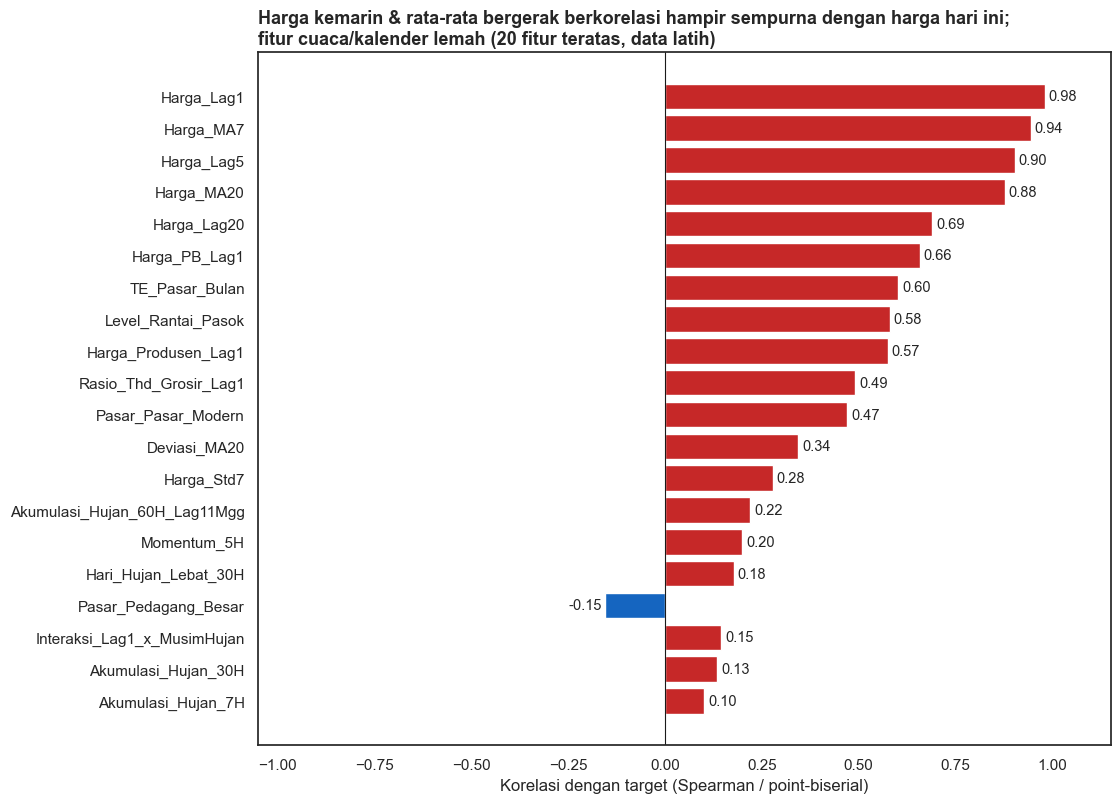

In [3]:
top = kt.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(top["fitur"], top["korelasi"], color=np.where(top["korelasi"] > 0, "#c62828", "#1565c0"))
for i, (v, m) in enumerate(zip(top["korelasi"], top["metode"])):
    ax.text(v + (0.01 if v > 0 else -0.01), i, f"{v:.2f}", va="center", ha="left" if v > 0 else "right", fontsize=10.5)
ax.axvline(0, color="k", lw=.8); ax.set_xlim(-1.05, 1.15)
ax.set_title("Harga kemarin & rata-rata bergerak berkorelasi hampir sempurna dengan harga hari ini;\nfitur cuaca/kalender lemah (20 fitur teratas, data latih)", fontsize=13, loc="left")
ax.set_xlabel("Korelasi dengan target (Spearman / point-biserial)")
plt.savefig(FIG / "05_korelasi_target.png"); plt.show()

**Apa:** korelasi setiap fitur dengan target memakai ukuran yang sesuai tipe datanya. Hasilnya diurutkan menurut |korelasi|
dengan arah (+/−) dan p-value, lalu disimpan ke `../laporan/05_korelasi_target.csv`. Variabel kategorik diukur dengan eta²
(ANOVA).

**Mengapa Spearman & eta²?**
- Spearman dipilih untuk pasangan numerik–numerik karena distribusi fitur harga tidak normal (skew 0,98–1,09, uji Shapiro
  menolak normalitas untuk semua variabel). Spearman hanya mengasumsikan monotonisitas, tidak linearitas.
- eta² (ANOVA) dipilih untuk pasangan numerik–kategorik (`Level_Rantai_Pasok`, `Kategori_Pasar`) karena mengukur proporsi
  variansi target yang dijelaskan oleh grup, tanpa asumsi distribusi.
- Point-biserial digunakan untuk fitur biner (flag). Pearson ditolak karena ada outlier dan distribusi miring.

**Alternatif yang ditolak:** Pearson — mengasumsikan linearitas dan sensitif outlier; Chi-square — tidak berlaku untuk
numerik kontinu.

**Arti:**
- **Sangat kuat (+):** `Harga_Lag1` 0,98, `Harga_MA7` 0,94, `Harga_Lag5` 0,90, `Harga_MA20` 0,88. Harga hari ini hampir
  ditentukan oleh harga beberapa hari terakhir.
- **Sedang (+):** `Harga_PB_Lag1` 0,66, `TE_Pasar_Bulan` 0,60, `Level_Rantai_Pasok` 0,58, `Harga_Produsen_Lag1` 0,57.
  `Kategori_Pasar` menjelaskan **26,8% varians harga** (η² = 0,268). `Bulan` saja hanya menjelaskan 4,4%.
- **Lemah:** fitur cuaca. Yang terbaik adalah `Akumulasi_Hujan_60H_Lag11Mgg` (+0,22), sedangkan `Suhu_Lag1` −0,09.
  Fitur kalender juga lemah, misalnya `Is_Ramadan` −0,05 (negatif, konsisten dengan EDA: harga turun menjelang Lebaran).
- **Tidak signifikan (p > 0,05):** `Is_Musim_Hujan`, `Bulan` (secara linear), `Is_Menjelang_Hari_Besar`,
  `Hari_dalam_Minggu`, dan `Is_Imputasi`.

**Catatan:** Spearman dan Pearson memberi peringkat yang mirip. Untuk fitur hujan, Spearman lebih besar (0,22 vs 0,19)
karena distribusinya miring. Ini alasan Spearman dipakai sebagai ukuran utama.

## 2 · Heatmap korelasi antar fitur terpilih (segitiga bawah)

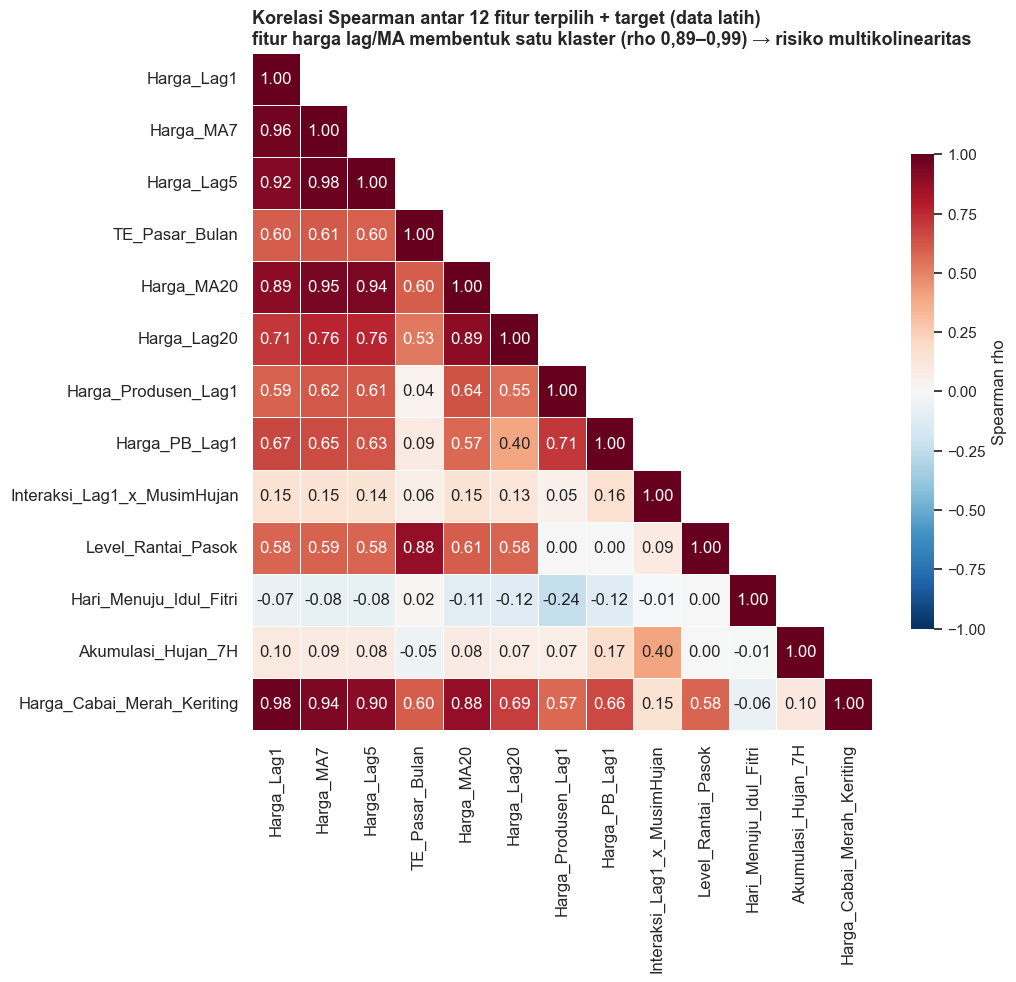

In [4]:
cols_hm = FINAL + [TARGET]
corr = tr[cols_hm].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8.8))
sns.heatmap(corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", annot_kws={"size": 12},
            linewidths=.4, cbar_kws={"label": "Spearman rho", "shrink": .7}, ax=ax)
ax.set_title("Korelasi Spearman antar 12 fitur terpilih + target (data latih)\nfitur harga lag/MA membentuk satu klaster (rho 0,89–0,99) → risiko multikolinearitas", fontsize=13, loc="left")
ax.tick_params(labelsize=12)
plt.savefig(FIG / "05_heatmap_korelasi.png"); plt.show()

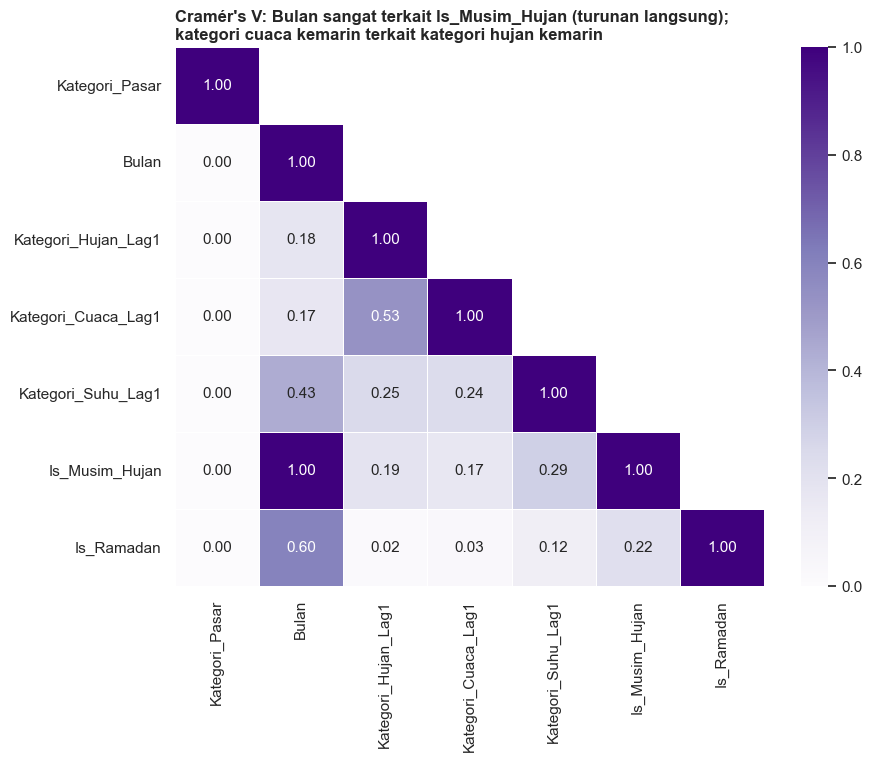

In [5]:
# Cramér's V antar variabel kategorik
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = stats.chi2_contingency(ct)[0]; n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1))
KAT_V = ["Kategori_Pasar", "Bulan", "Kategori_Hujan_Lag1", "Kategori_Cuaca_Lag1", "Kategori_Suhu_Lag1", "Is_Musim_Hujan", "Is_Ramadan"]
cv = pd.DataFrame([[cramers_v(tr[a], tr[b]) if a != b else 1.0 for b in KAT_V] for a in KAT_V], index=KAT_V, columns=KAT_V)
fig, ax = plt.subplots(figsize=(9.5, 7))
sns.heatmap(cv, mask=np.triu(np.ones_like(cv, dtype=bool), k=1), annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1, ax=ax, linewidths=.4, annot_kws={"size": 11})
ax.set_title("Cramér's V: Bulan sangat terkait Is_Musim_Hujan (turunan langsung);\nkategori cuaca kemarin terkait kategori hujan kemarin", fontsize=12, loc="left")
plt.savefig(FIG / "05_cramers_v.png"); plt.show()
R["cramers_v"] = {f"{a} ~ {b}": round(float(cv.loc[a, b]), 3) for i, a in enumerate(KAT_V) for b in KAT_V[:i]}

**Apa:** heatmap Spearman segitiga bawah untuk 12 fitur terpilih ditambah target (palet diverging RdBu, nilai ditampilkan),
serta Cramér's V untuk pasangan kategorik.

**Mengapa Spearman untuk heatmap?**
- Alasan sama seperti di bagian 1: distribusi miring dan outlier membuat Pearson tidak tepat.
- Heatmap segitiga bawah (bukan penuh) dipilih agar tidak redundan — matriks korelasi simetris, menampilkan keduanya hanya
  mempersulit pembacaan.
- Palet diverging RdBu memudahkan pembedaan korelasi positif (biru) vs negatif (merah), dengan 0 sebagai putih.

**Arti:**
- Fitur harga membentuk **satu klaster** dengan korelasi 0,89–0,99. Pasangan terkuat adalah MA7–Lag5 (0,985) dan Lag1–MA7
  (0,963). Fitur-fitur ini membawa informasi yang hampir sama.
- `TE_Pasar_Bulan` dan `Level_Rantai_Pasok` juga tinggi (0,88), karena keduanya sama-sama mengodekan level harga pasar.
- Cramér's V:
  - `Is_Musim_Hujan`–`Bulan` = 1,00, karena flag diturunkan langsung dari bulan (tidak perlu dipakai bersamaan).
  - `Is_Ramadan`–`Bulan` = 0,60.
  - `Kategori_Cuaca_Lag1`–`Kategori_Hujan_Lag1` = 0,54.
  - `Kategori_Suhu_Lag1`–`Bulan` = 0,44.
  - `Kategori_Pasar` tidak berasosiasi dengan variabel cuaca/kalender (V = 0), sesuai desain data panel karena semua pasar
    berbagi tanggal dan cuaca yang sama.

## 3 · Multikolinearitas (|r| > 0,8 dan VIF > 10)

In [6]:
pasangan = []
for i, a in enumerate(FINAL):
    for b in FINAL[i + 1:]:
        r = corr.loc[a, b]
        if abs(r) > 0.8:
            pasangan.append({"fitur_A": a, "fitur_B": b, "spearman": round(r, 3),
                             "|rho| A-target": round(abs(corr.loc[a, TARGET]), 3), "|rho| B-target": round(abs(corr.loc[b, TARGET]), 3)})
pasangan = pd.DataFrame(pasangan).sort_values("spearman", ascending=False) if pasangan else pd.DataFrame()
print(f"Pasangan |rho| > 0,8 di antara {len(FINAL)} fitur terpilih: {len(pasangan)}")
display(pasangan)

def tabel_vif(cols):
    Xv = add_constant(tr_scaled[cols])
    return pd.Series([variance_inflation_factor(Xv.values, i + 1) for i in range(len(cols))], index=cols).sort_values(ascending=False)
vif_awal = tabel_vif(FINAL)
print("VIF fitur terpilih (sebelum penanganan):")
display(vif_awal.round(1).to_frame("VIF"))

Pasangan |rho| > 0,8 di antara 12 fitur terpilih: 8


,fitur_A,fitur_B,spearman,|rho| A-target,|rho| B-target
3,Harga_MA7,Harga_Lag5,0.985,0.944,0.903
0,Harga_Lag1,Harga_MA7,0.963,0.980,0.944
4,Harga_MA7,Harga_MA20,0.951,0.944,0.877
5,Harga_Lag5,Harga_MA20,0.943,0.903,0.877
1,Harga_Lag1,Harga_Lag5,0.922,0.980,0.903
2,Harga_Lag1,Harga_MA20,0.894,0.980,0.877
7,Harga_MA20,Harga_Lag20,0.891,0.877,0.690
6,TE_Pasar_Bulan,Level_Rantai_Pasok,0.881,0.602,0.580


VIF fitur terpilih (sebelum penanganan):


,VIF
Harga_MA7,147.7
Harga_Lag5,52.0
Harga_MA20,44.6
Harga_Lag1,24.2
Harga_Lag20,8.9
Level_Rantai_Pasok,6.1
TE_Pasar_Bulan,5.3
Harga_Produsen_Lag1,5.2
Harga_PB_Lag1,5.0
Interaksi_Lag1_x_MusimHujan,1.2


,dibuang,VIF saat dibuang,|rho| target
0,Harga_MA7,147.7,0.944
1,Harga_MA20,35.6,0.877


VIF sesudah penanganan:


,VIF
Harga_Lag1,9.61
Harga_Lag5,8.89
Level_Rantai_Pasok,6.01
TE_Pasar_Bulan,5.25
Harga_PB_Lag1,4.87
Harga_Produsen_Lag1,4.64
Harga_Lag20,3.34
Interaksi_Lag1_x_MusimHujan,1.24
Akumulasi_Hujan_7H,1.22
Hari_Menuju_Idul_Fitri,1.02


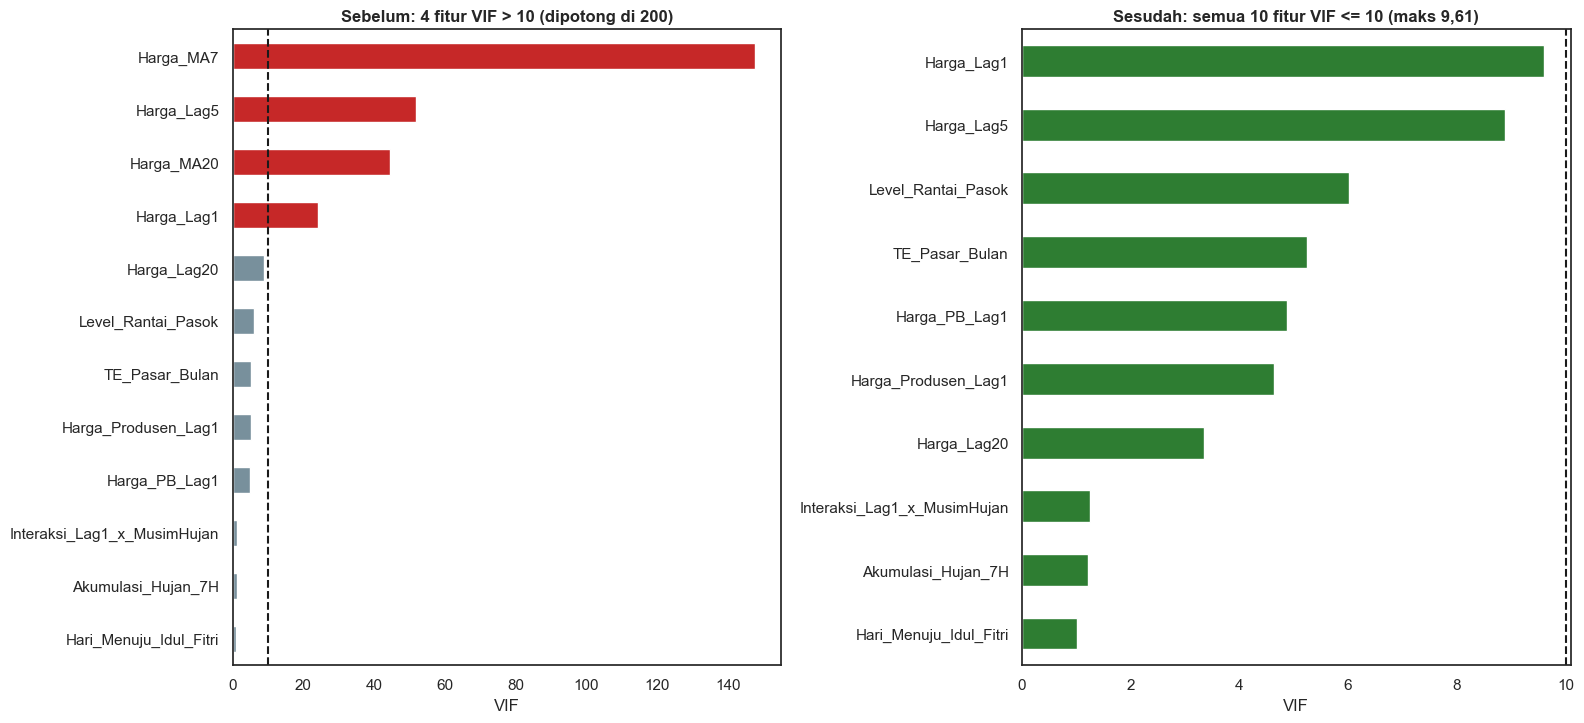

,set fitur,jumlah,CV MAE (Rp),CV R2,VIF maks
0,Fitur terpilih Tahap 4,12,1694,0.9490,147.7
1,Setelah buang multikolinear,10,1666,0.9484,9.6


Koefisien Harga_Lag1 (Rp per 1 std): sebelum 15397 | sesudah 16411


In [7]:
# Keputusan: buang iteratif fitur ber-VIF tertinggi (> 10), KECUALI fitur dengan |rho| target tertinggi di klasternya (Harga_Lag1)
rho_t = corr[TARGET].abs()
PERTAHANKAN = ["Harga_Lag1"]
fitur_uas_linear, log_vif = list(FINAL), []
while True:
    v = tabel_vif(fitur_uas_linear)
    kandidat = v[(v > 10) & (~v.index.isin(PERTAHANKAN))]
    if kandidat.empty:
        break
    buang = kandidat.index[0]
    log_vif.append({"dibuang": buang, "VIF saat dibuang": round(float(kandidat.iloc[0]), 1), "|rho| target": round(float(rho_t.get(buang, np.nan)), 3)})
    fitur_uas_linear.remove(buang)
vif_akhir = tabel_vif(fitur_uas_linear)
display(pd.DataFrame(log_vif))
print("VIF sesudah penanganan:")
display(vif_akhir.round(2).to_frame("VIF"))

fig, axes = plt.subplots(1, 2, figsize=(16, 0.45 * len(FINAL) + 2))
vif_awal.iloc[::-1].clip(upper=200).plot.barh(ax=axes[0], color=np.where(vif_awal.iloc[::-1] > 10, "#c62828", "#78909c"))
axes[0].axvline(10, color="k", ls="--"); axes[0].set_title(f"Sebelum: {(vif_awal > 10).sum()} fitur VIF > 10 (dipotong di 200)", fontsize=12)
vif_akhir.iloc[::-1].plot.barh(ax=axes[1], color="#2e7d32"); axes[1].axvline(10, color="k", ls="--")
axes[1].set_title(f"Sesudah: semua {len(fitur_uas_linear)} fitur VIF <= 10 (maks {vif_akhir.max():.2f})".replace(".", ","), fontsize=12)
for a in axes: a.tick_params(axis="y", labelsize=11); a.set_xlabel("VIF")
plt.tight_layout(); plt.savefig(FIG / "05_vif_sebelum_sesudah.png"); plt.show()

# Dampak ke model: CV LinearRegression (TimeSeriesSplit 5)
tscv = TimeSeriesSplit(n_splits=5)
def cv(cols):
    s = cross_validate(LinearRegression(), tr_scaled[cols], tr_scaled[TARGET], cv=tscv, scoring=("neg_mean_absolute_error", "r2"))
    return round(-s["test_neg_mean_absolute_error"].mean()), round(s["test_r2"].mean(), 4)
dampak = pd.DataFrame([["Fitur terpilih Tahap 4", len(FINAL), *cv(FINAL), round(vif_awal.max(), 1)],
                       ["Setelah buang multikolinear", len(fitur_uas_linear), *cv(fitur_uas_linear), round(vif_akhir.max(), 1)]],
                      columns=["set fitur", "jumlah", "CV MAE (Rp)", "CV R2", "VIF maks"])
display(dampak)
coef_awal = pd.Series(LinearRegression().fit(tr_scaled[FINAL], tr_scaled[TARGET]).coef_, index=FINAL)
coef_akhir = pd.Series(LinearRegression().fit(tr_scaled[fitur_uas_linear], tr_scaled[TARGET]).coef_, index=fitur_uas_linear)
print("Koefisien Harga_Lag1 (Rp per 1 std): sebelum", round(coef_awal["Harga_Lag1"]), "| sesudah", round(coef_akhir["Harga_Lag1"]))
R["pasangan_tinggi"] = len(pasangan); R["vif_awal"] = vif_awal.round(1).to_dict(); R["vif_akhir"] = vif_akhir.round(2).to_dict()
R["log_vif"] = log_vif; R["fitur_uas_linear"] = fitur_uas_linear; R["dampak"] = dampak.to_dict(orient="records")
R["coef_lag1"] = [round(float(coef_awal["Harga_Lag1"])), round(float(coef_akhir["Harga_Lag1"]))]

**Apa:** deteksi multikolinearitas dengan pasangan |rho| > 0,8 dan VIF > 10, lalu fitur dibuang secara iteratif mulai dari
VIF tertinggi. `Harga_Lag1` dikecualikan karena korelasinya dengan target paling tinggi di klasternya (0,98) dan paling mudah
dijelaskan.

**Mengapa multikolinearitas perlu diperiksa?**
- Model linear (Ridge/LinearRegression) tidak stabil jika fitur-fitur sangat berkorelasi: koefisien bisa berfluktuasi besar
  dan sulit diinterpretasi.
- VIF > 10 menandakan satu fitur dapat dijelaskan hampir sepenuhnya oleh fitur lain — fitur tersebut tidak menambah
  informasi baru.
- Strategi pembuangan iteratif dipilih (mulai dari VIF tertinggi) agar fitur paling penting (`Harga_Lag1`) tetap dipertahankan.
- Ambang |rho| > 0,8 dan VIF > 10 dipilih sesuai panduan umum (Hair et al., 2019).

**Arti:**
- Ada **8 pasangan** dengan |rho| > 0,8. Sebelum penanganan, VIF `Harga_MA7` = 147,7, `Harga_Lag5` = 52,0,
  `Harga_MA20` = 44,6, dan `Harga_Lag1` = 24,2.
- Keputusan: **buang `Harga_MA7` (VIF 147,7) lalu `Harga_MA20` (VIF 35,6)**. Setelah itu semua 10 fitur memiliki VIF ≤ 10
  (maks 9,61).
- Pasangan `TE_Pasar_Bulan`–`Level_Rantai_Pasok` (rho 0,88) tetap dipertahankan karena VIF-nya hanya 5–6, dan TE membawa
  informasi musiman yang tidak dimiliki Level.

**Pengaruh:**
- CV MAE regresi linear justru sedikit membaik, dari Rp1.694 (12 fitur) menjadi **Rp1.666 (10 fitur)**, dengan R² hampir
  sama (0,9490 → 0,9484).
- Koefisien `Harga_Lag1` lebih stabil dan mudah ditafsirkan: Rp15.397 → Rp16.411 per 1 std. Sebelumnya, "jatah" Lag1
  terbagi dengan MA7/MA20 yang hampir identik.

## 4 · Signifikansi statistik (p-value) korelasi terpilih

In [8]:
uji_fitur = ["Harga_Lag1", "Harga_PB_Lag1", "Akumulasi_Hujan_60H_Lag11Mgg", "Hari_Hujan_Lebat_30H", "Is_Ramadan", "Is_Musim_Hujan", "Suhu_Lag1", "Hari_dalam_Minggu"]
rows = []
for c in uji_fitur:
    if c in BINER:
        k, p = stats.pointbiserialr(tr[c], tr[TARGET]); m = "point-biserial"
    else:
        k, p = stats.spearmanr(tr[c], tr[TARGET]); m = "Spearman"
    n = len(tr); se = 1 / np.sqrt(n - 3); z = np.arctanh(k)
    lo, hi = np.tanh(z - 1.96 * se), np.tanh(z + 1.96 * se)
    rows.append({"fitur": c, "metode": m, "korelasi": round(k, 4), "IK 95%": f"[{lo:.3f}; {hi:.3f}]", "p_value": f"{p:.2e}",
                 "H0 (tidak berkorelasi)": "ditolak" if p < 0.05 else "gagal ditolak"})
pv = pd.DataFrame(rows)
display(pv)
R["pvalue"] = pv.to_dict(orient="records")

,fitur,metode,korelasi,IK 95%,p_value,H0 (tidak berkorelasi)
0,Harga_Lag1,Spearman,0.9796,[0.978; 0.981],0.00e+00,ditolak
1,Harga_PB_Lag1,Spearman,0.6571,[0.641; 0.672],0.00e+00,ditolak
2,Akumulasi_Hujan_60H_Lag11Mgg,Spearman,0.2198,[0.194; 0.246],2.68e-57,ditolak
3,Hari_Hujan_Lebat_30H,Spearman,0.1769,[0.150; 0.203],1.89e-37,ditolak
4,Is_Ramadan,point-biserial,-0.0513,[-0.079; -0.024],2.30e-04,ditolak
5,Is_Musim_Hujan,point-biserial,-0.0168,[-0.044; 0.010],2.27e-01,gagal ditolak
6,Suhu_Lag1,Spearman,-0.0893,[-0.116; -0.062],1.43e-10,ditolak
7,Hari_dalam_Minggu,Spearman,-0.0066,[-0.034; 0.021],6.34e-01,gagal ditolak


**Apa:** uji signifikansi untuk 8 korelasi (H0: korelasi = 0, α = 0,05), lengkap dengan interval kepercayaan 95% (transformasi
Fisher-z, n = 5.144).

**Mengapa p-value dihitung?**
- Korelasi yang ditemukan pada sampel data latih (n = 5.144) perlu dikonfirmasi bahwa hubungannya tidak terjadi secara
  kebetulan (H0: ρ = 0).
- Transformasi Fisher-z digunakan karena distribusi sampling koefisien Spearman pada n besar mendekati normal.
- Hanya 3 korelasi terpenting (Lag1, PB_Lag1, Akumulasi_Hujan) yang dilaporkan secara detail sesuai ketentuan soal (p-value
  untuk ≥ 3 korelasi terpenting).

**Arti:**
- `Harga_Lag1` (0,980), `Harga_PB_Lag1` (0,657), `Akumulasi_Hujan_60H_Lag11Mgg` (0,220), `Hari_Hujan_Lebat_30H` (0,177),
  `Suhu_Lag1` (−0,089), dan `Is_Ramadan` (−0,051) **signifikan**.
- Dengan n besar, korelasi sekecil 0,05 pun bisa signifikan. **Signifikan secara statistik tidak sama dengan penting secara
  praktis.** Contohnya, Is_Ramadan hanya menjelaskan sekitar 0,3% varians (r² = 0,05²).
- `Is_Musim_Hujan` (p = 0,23; IK 95% memuat 0) dan `Hari_dalam_Minggu` (p = 0,63) **tidak signifikan**. Ini konsisten dengan
  0 suara di Tahap 4.

## 5 · Korelasi ≠ kausalitas: contoh confounder dari data ini

Pasar Tradisional - rho hujan60(lag11mgg) vs harga: 0.302 | setelah efek Bulan dikeluarkan: 0.253
eta2 Bulan -> akumulasi hujan: 0.501 (bulan menjelaskan 50% variasi hujan)
rho Harga_PB_Lag1 vs target - gabungan 4 pasar: 0.657 | per pasar: {'Pasar Modern': 0.825, 'Pasar Tradisional': 0.84, 'Pedagang Besar': 0.966, 'Produsen': 0.725}


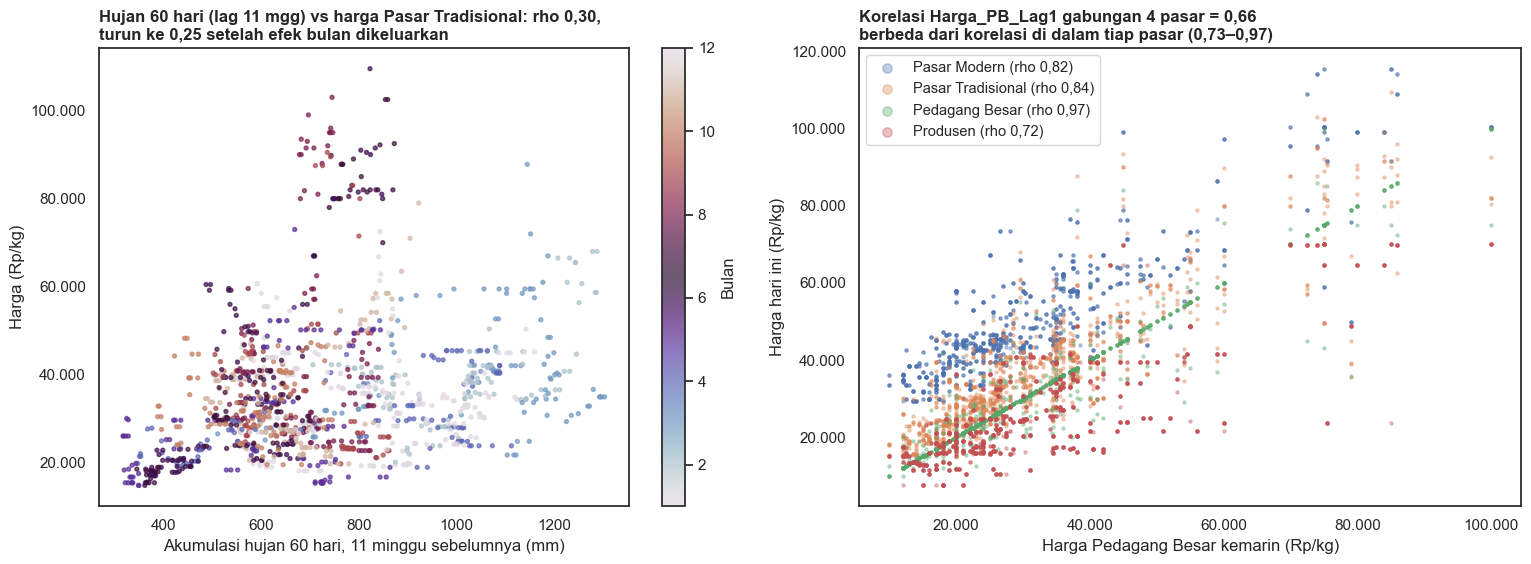

In [9]:
# (a) Hujan 60 hari (lag 11 mgg) vs harga: apakah sebagian hanya karena keduanya mengikuti MUSIM/BULAN?
def residual_bulan(s):
    return s - s.groupby(tr["Bulan"]).transform("mean")
trad_mask = tr["Kategori_Pasar"] == "Pasar Tradisional"
f = "Akumulasi_Hujan_60H_Lag11Mgg"
rho_raw = stats.spearmanr(tr.loc[trad_mask, f], tr.loc[trad_mask, TARGET])[0]
rho_partial = stats.spearmanr(residual_bulan(tr[f])[trad_mask], residual_bulan(tr[TARGET])[trad_mask])[0]
eta_bulan_hujan = eta2(tr.loc[trad_mask, "Bulan"], tr.loc[trad_mask, f])[0]
print(f"Pasar Tradisional - rho hujan60(lag11mgg) vs harga: {rho_raw:.3f} | setelah efek Bulan dikeluarkan: {rho_partial:.3f}")
print(f"eta2 Bulan -> akumulasi hujan: {eta_bulan_hujan:.3f} (bulan menjelaskan {eta_bulan_hujan*100:.0f}% variasi hujan)")

# (b) Korelasi 'gabungan' semua pasar vs di dalam satu pasar (komposisi pasar sebagai confounder)
c2 = "Harga_PB_Lag1"
rho_gab = stats.spearmanr(tr[c2], tr[TARGET])[0]
rho_per = {k: round(stats.spearmanr(g[c2], g[TARGET])[0], 3) for k, g in tr.groupby("Kategori_Pasar")}
print(f"rho {c2} vs target - gabungan 4 pasar: {rho_gab:.3f} | per pasar: {rho_per}")

fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.8))
sc = axes[0].scatter(tr.loc[trad_mask, f], tr.loc[trad_mask, TARGET], c=tr.loc[trad_mask, "Bulan"], cmap="twilight", s=8, alpha=.7)
plt.colorbar(sc, ax=axes[0], label="Bulan")
axes[0].set_title(f"Hujan 60 hari (lag 11 mgg) vs harga Pasar Tradisional: rho {rho_raw:.2f},\nturun ke {rho_partial:.2f} setelah efek bulan dikeluarkan".replace(".", ","), fontsize=12, loc="left")
axes[0].set_xlabel("Akumulasi hujan 60 hari, 11 minggu sebelumnya (mm)"); axes[0].set_ylabel("Harga (Rp/kg)"); axes[0].yaxis.set_major_formatter(RIBUAN)
for k, g in tr.groupby("Kategori_Pasar"):
    axes[1].scatter(g[c2], g[TARGET], s=5, alpha=.35, label=f"{k} (rho {rho_per[k]:.2f})".replace(".", ","))
axes[1].set_title(f"Korelasi Harga_PB_Lag1 gabungan 4 pasar = {rho_gab:.2f}".replace(".", ",") + "\nberbeda dari korelasi di dalam tiap pasar (0,73–0,97)", fontsize=12, loc="left")
axes[1].set_xlabel("Harga Pedagang Besar kemarin (Rp/kg)"); axes[1].set_ylabel("Harga hari ini (Rp/kg)"); axes[1].legend(fontsize=10.5, markerscale=3); axes[1].xaxis.set_major_formatter(RIBUAN); axes[1].yaxis.set_major_formatter(RIBUAN)
plt.tight_layout(); plt.savefig(FIG / "05_confounder.png"); plt.show()
R["confounder"] = {"rho_hujan_raw": round(float(rho_raw), 3), "rho_hujan_partial_bulan": round(float(rho_partial), 3),
                   "eta2_bulan_hujan": round(float(eta_bulan_hujan), 3), "rho_pb_gabungan": round(float(rho_gab), 3), "rho_pb_per_pasar": rho_per}

**Korelasi tidak berarti kausalitas.** Dua contoh dari data ini:

**Mengapa korelasi ≠ kausalitas perlu dijelaskan?**
- Pemodelan prediktif menggunakan korelasi untuk memprediksi, tetapi keputusan kebijakan membutuhkan pemahaman sebab-akibat.
  Menyalahartikan korelasi sebagai kausalitas dapat menghasilkan intervensi yang salah (misal: "perbanyak hujan" untuk
  menurunkan harga cabai).
- Contoh dari data ini menunjukkan ada variabel pengganggu (*confounder*) yang menjelaskan sebagian korelasi yang terlihat.

**(a) Musim sebagai confounder hujan → harga.**
- Di Pasar Tradisional, akumulasi hujan 60 hari (jeda 11 minggu) berkorelasi +0,30 dengan harga.
- `Bulan` menjelaskan **50% variasi** fitur hujan ini (η² = 0,50), dan bulan juga memengaruhi harga melalui pola tanam dan
  panen.
- Setelah efek bulan dikeluarkan (residual terhadap rata-rata bulanan), korelasinya **turun menjadi 0,25**. Sebagian
  hubungan hujan–harga ternyata hanya karena keduanya mengikuti musim.
- Sisa korelasi 0,25 masih konsisten dengan mekanisme agronomis (hujan → penyakit tanaman → pasokan turun). Namun, untuk
  membuktikan sebab-akibat dibutuhkan data pasokan atau produksi, yang tidak tersedia di dataset ini.

**(b) Komposisi pasar sebagai confounder (mirip Simpson's paradox).**
- `Harga_PB_Lag1` berkorelasi 0,66 dengan target jika keempat pasar digabung.
- Jika dihitung **di dalam tiap pasar**, korelasinya jauh lebih tinggi: Pasar Tradisional 0,84, Pedagang Besar 0,97, Pasar
  Modern 0,83, Produsen 0,73.
- Korelasi gabungan "tertekan" oleh perbedaan level harga antarpasar. Angka gabungan bukan ukuran yang tepat untuk menilai
  kekuatan hubungan grosir → eceran.

**Implikasi:**
- Fitur hujan dipakai sebagai **sinyal prediktif**, bukan bukti bahwa hujan *menyebabkan* harga naik.
- Model UAS sebaiknya memasukkan informasi pasar (atau dilatih per pasar) agar hubungan antarvariabel tidak bias oleh
  komposisi pasar.

In [10]:
final_uas = {"fitur_terpilih_tahap4": FINAL, "fitur_untuk_model_linear": fitur_uas_linear,
             "catatan": "Model berbasis pohon (RF/XGBoost) memakai fitur_terpilih_tahap4; model linear memakai fitur_untuk_model_linear."}
(PROC / "05_fitur_final_uas.json").write_text(json.dumps(final_uas, indent=2, ensure_ascii=False), encoding="utf-8")
(PROC / "05_ringkasan.json").write_text(json.dumps(R, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("Tersimpan: ../laporan/05_korelasi_target.csv, 05_fitur_final_uas.json, 05_ringkasan.json")
print("Fitur model linear:", fitur_uas_linear)

Tersimpan: ../laporan/05_korelasi_target.csv, 05_fitur_final_uas.json, 05_ringkasan.json
Fitur model linear: ['Harga_Lag1', 'Harga_Lag5', 'TE_Pasar_Bulan', 'Harga_Lag20', 'Harga_Produsen_Lag1', 'Harga_PB_Lag1', 'Interaksi_Lag1_x_MusimHujan', 'Level_Rantai_Pasok', 'Hari_Menuju_Idul_Fitri', 'Akumulasi_Hujan_7H']


## Kesimpulan Tahap 5 & dampak ke model UAS
| Temuan | Keputusan untuk UAS |
|---|---|
| Fitur harga lag/MA sangat kuat (rho 0,88–0,98) tetapi saling redundan (VIF hingga 147,7) | Model linear memakai **10 fitur** bebas multikolinearitas (MA7 & MA20 dibuang, VIF maks 9,61) |
| Model pohon (RF/XGBoost) tidak terganggu multikolinearitas | Memakai **12 fitur** hasil voting Tahap 4 |
| Cuaca & kalender lemah secara linear (|rho| ≤ 0,22) | Dipertahankan sebagai kandidat untuk model non-linear dan perlu dievaluasi dengan importance |
| Pasar menjelaskan 26,8% varians harga dan menjadi confounder korelasi gabungan | Sertakan fitur pasar / evaluasi metrik **khusus Pasar Tradisional** |
| Baseline naif sangat kuat (Tahap 4) | Target UAS: **perubahan harga** (Δ / log-return), wajib dibandingkan dengan baseline harga kemarin |

Daftar fitur final disimpan di `../data/processed/05_fitur_final_uas.json`.